# Telecom Churn Prediction

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [5]:
# loading dataset
df=pd.read_csv(r'C:\Users\shrey\OneDrive\Desktop\Churn prediction\Telcom-Customer-Churn.csv')

In [6]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [8]:
df['TotalCharges'].unique()

<ArrowStringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',
 ...
 '2625.25', '6886.25',  '1495.1',   '743.3',  '1419.4',  '1990.5',  '7362.9',
  '346.45',   '306.6',  '6844.5']
Length: 6531, dtype: str

In [9]:
df['TotalCharges']= df['TotalCharges'].replace('',np.nan,inplace=True)

C:\Users\shrey\AppData\Local\Temp\ipykernel_1224\2269057654.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['TotalCharges']= df['TotalCharges'].replace('',np.nan,inplace=True)


In [10]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors='coerce')

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [12]:
# checking duplicates

In [13]:
df.duplicated().sum()

np.int64(0)

# checking missing value

In [14]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [15]:
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [16]:
# checking skewness 

<Axes: >

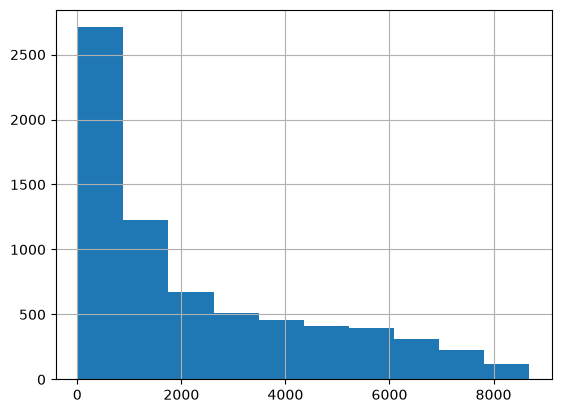

In [17]:
df['TotalCharges'].hist()

In [18]:
median= df['TotalCharges'].median()

In [19]:
df['TotalCharges']=df['TotalCharges'].fillna(median, inplace=True)

C:\Users\shrey\AppData\Local\Temp\ipykernel_1224\3886904057.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['TotalCharges']=df['TotalCharges'].fillna(median, inplace=True)


In [20]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [21]:
df['OnlineSecurity'].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [22]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [24]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<Axes: xlabel='TotalCharges'>

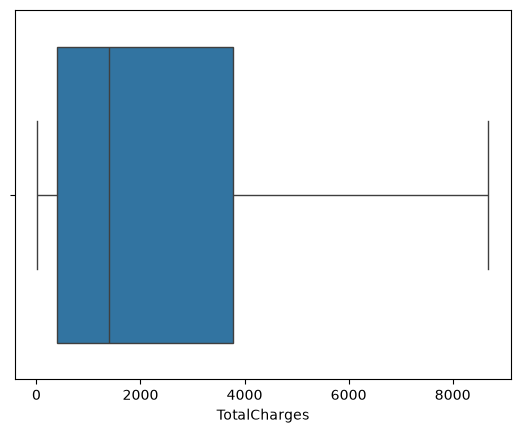

In [25]:
sns.boxplot(x='TotalCharges',data=df)

In [26]:
# splitting numerical and categorical col 

In [27]:
df_num=df.select_dtypes(['int64','float64'])
df_num

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,29.85,29.85
1,0,34,56.95,1889.50
2,0,2,53.85,108.15
3,0,45,42.30,1840.75
4,0,2,70.70,151.65
...,...,...,...,...
7038,0,24,84.80,1990.50
7039,0,72,103.20,7362.90
7040,0,11,29.60,346.45
7041,1,4,74.40,306.60


In [28]:
df_cat=df.select_dtypes('str')
df_cat

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,7590-VHVEG,Female,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,No
1,5575-GNVDE,Male,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,No
2,3668-QPYBK,Male,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,Yes
3,7795-CFOCW,Male,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),No
4,9237-HQITU,Female,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,Yes,Yes,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,No
7039,2234-XADUH,Female,Yes,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),No
7040,4801-JZAZL,Female,Yes,Yes,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
7041,8361-LTMKD,Male,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,Yes


In [29]:
# Label encoding technique ( categorical to numerical)

In [30]:
for i in df_cat:

  from sklearn.preprocessing import LabelEncoder

  le = LabelEncoder()

  df_cat[i]= le.fit_transform(df_cat[i])

In [31]:
df_cat

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,5375,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0
1,3962,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0
2,2564,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,1
3,5535,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0
4,6511,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,4853,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0
7039,1525,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0
7040,3367,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0
7041,5934,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1


In [32]:
df_cat=df_cat.drop(columns='customerID')
df_cat

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0
1,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0
2,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,1
3,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0
4,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0
7039,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0
7040,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0
7041,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1


In [33]:
# combining num col and cat col

In [34]:
df_new= pd.concat([df_num,df_cat],axis=1)
df_new

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,0,1,29.85,29.85,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0
2,0,2,53.85,108.15,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0
7039,0,72,103.20,7362.90,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0
7040,0,11,29.60,346.45,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0
7041,1,4,74.40,306.60,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1


In [35]:
# Independent and dependent

In [36]:
X= df_new.drop('Churn',axis=1)

y=df_new['Churn']

In [37]:
X

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod
0,0,1,29.85,29.85,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2
1,0,34,56.95,1889.50,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3
2,0,2,53.85,108.15,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3
3,0,45,42.30,1840.75,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0
4,0,2,70.70,151.65,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,0,24,84.80,1990.50,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3
7039,0,72,103.20,7362.90,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1
7040,0,11,29.60,346.45,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2
7041,1,4,74.40,306.60,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3


In [38]:
y

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [39]:
# splitting the dataset into training and testing

In [40]:
from sklearn.model_selection import train_test_split

In [41]:
X_train,X_test,y_train,y_test= train_test_split(X,y, test_size=0.30,random_state=42)

In [42]:
print(X_train.shape,y_train.shape)

(4930, 19) (4930,)


In [43]:
print(X_test.shape,y_test.shape)

(2113, 19) (2113,)


In [44]:
# scaling the number

from sklearn.preprocessing import MinMaxScaler


In [45]:
mm=MinMaxScaler()

In [46]:
X_train= mm.fit_transform(X_train)

X_test =mm.transform(X_test)

In [47]:
X_train

array([[0.        , 0.75      , 0.52267065, ..., 0.5       , 1.        ,
        0.66666667],
       [0.        , 0.01388889, 0.62082711, ..., 0.        , 1.        ,
        0.66666667],
       [0.        , 0.18055556, 0.01046338, ..., 0.5       , 0.        ,
        0.33333333],
       ...,
       [0.        , 0.16666667, 0.02889885, ..., 0.        , 1.        ,
        0.66666667],
       [1.        , 0.16666667, 0.80916791, ..., 0.        , 1.        ,
        0.66666667],
       [0.        , 0.36111111, 0.01544594, ..., 0.5       , 0.        ,
        0.33333333]], shape=(4930, 19))

In [48]:
X_test

array([[0.        , 0.01388889, 0.06527155, ..., 0.        , 1.        ,
        0.66666667],
       [0.        , 0.56944444, 0.06975585, ..., 0.        , 1.        ,
        0.        ],
       [0.        , 0.72222222, 0.01096163, ..., 1.        , 0.        ,
        1.        ],
       ...,
       [0.        , 0.83333333, 0.42102641, ..., 1.        , 0.        ,
        0.        ],
       [0.        , 0.27777778, 0.72197309, ..., 0.        , 1.        ,
        0.33333333],
       [0.        , 0.30555556, 0.32735426, ..., 0.        , 1.        ,
        0.66666667]], shape=(2113, 19))

# Applying the Logistic Regression

In [49]:
df_new['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In [50]:
from sklearn.linear_model import LogisticRegression

In [51]:
lg= LogisticRegression(max_iter =1000)

In [52]:
lg.fit(X_train,y_train)

y_pred = lg.predict(X_test)
y_pred

array([1, 0, 0, ..., 0, 1, 0], shape=(2113,))

In [53]:
compare=pd.DataFrame({'Actual_value': y_test,'Predicted_value': y_pred})
compare

,Actual_value,Predicted_value
185,1,1
2715,0,0
3825,0,0
1807,1,1
132,0,0
...,...,...
5522,1,1
6377,1,1
5500,0,0
2392,0,1


In [54]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report

In [55]:
acc = accuracy_score(y_test,y_pred)
print('Accuracy score:', acc)

Accuracy score: 0.8111689540937056


In [56]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1539
           1       0.68      0.57      0.62       574

    accuracy                           0.81      2113
   macro avg       0.77      0.73      0.75      2113
weighted avg       0.80      0.81      0.81      2113



In [57]:
from sklearn.metrics import confusion_matrix

print(confusion_matrix(y_test,y_pred))

[[1389  150]
 [ 249  325]]


In [58]:
# SMOTE TECHNIQUE

In [59]:
!pip install imblearn

In [60]:
from imblearn.over_sampling import SMOTE

In [61]:
smote = SMOTE(random_state=42)

In [62]:
X_train_resample, y_train_resample = smote.fit_resample(X_train,y_train)

In [63]:
X_train_resample.shape

(7270, 19)

In [64]:
y_train_resample.value_counts()

Churn
0    3635
1    3635
Name: count, dtype: int64

In [65]:
lg= LogisticRegression()

lg.fit(X_train_resample,y_train_resample)

y_pred = lg.predict(X_test)
y_pred


array([1, 0, 0, ..., 0, 1, 0], shape=(2113,))

In [66]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.92      0.73      0.82      1539
           1       0.54      0.82      0.65       574

    accuracy                           0.76      2113
   macro avg       0.73      0.78      0.73      2113
weighted avg       0.81      0.76      0.77      2113



In [67]:
from sklearn.metrics import roc_auc_score

In [68]:
y_prob= lg.predict_proba(X_test)[:,1]

In [69]:
roc_auc = roc_auc_score(y_test,y_prob)
roc_auc

0.8573828428342763

<Axes: xlabel='Churn', ylabel='count'>

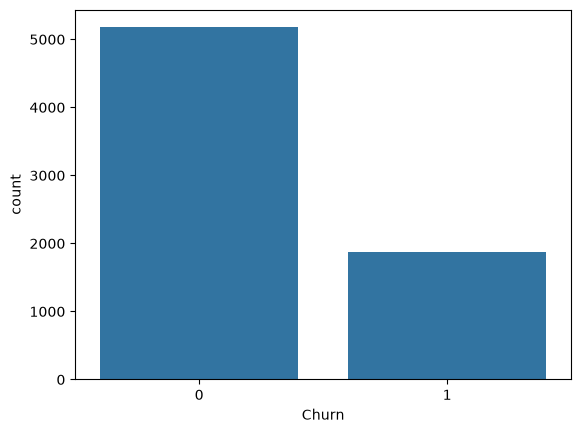

In [70]:
sns.countplot(x='Churn',data=df_new)

Text(0.5, 1.0, 'Churn %')

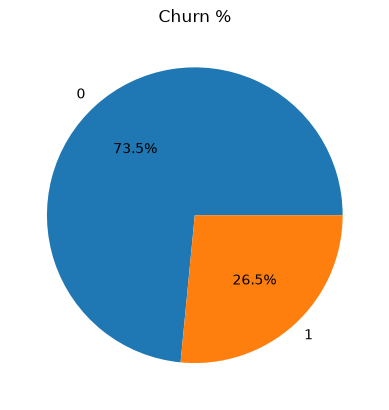

In [71]:
df_new['Churn'].value_counts().plot.pie(autopct= '%1.1f%%')
plt.title('Churn %')

In [72]:
# Decision tree algo

In [73]:
from sklearn.tree import DecisionTreeClassifier

In [74]:
dc = DecisionTreeClassifier(random_state=42)

In [75]:
dc.fit(X_train_resample,y_train_resample)

y_pred =dc.predict(X_test)

In [76]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.82      0.79      0.80      1539
           1       0.49      0.53      0.51       574

    accuracy                           0.72      2113
   macro avg       0.65      0.66      0.66      2113
weighted avg       0.73      0.72      0.72      2113



In [77]:
y_prob= dc.predict_proba(X_test)[:,1]

In [78]:
print(roc_auc_score(y_test,y_prob))

0.6615539526322582


In [79]:
dc.score(X_train_resample,y_train_resample)

0.9988995873452545

In [80]:
dc.score(X_test,y_test)

0.7203028868906768

In [81]:
dc1 = DecisionTreeClassifier(max_depth=2)


In [82]:
dc1.fit(X_train_resample,y_train_resample)

y_pred_dc1 = dc1.predict(X_test)

In [83]:
print(classification_report(y_test,y_pred_dc1))


              precision    recall  f1-score   support

           0       0.88      0.74      0.80      1539
           1       0.51      0.73      0.60       574

    accuracy                           0.74      2113
   macro avg       0.70      0.74      0.70      2113
weighted avg       0.78      0.74      0.75      2113



In [84]:
# without smote (not resample)

In [85]:
dc2 = DecisionTreeClassifier(random_state=42)

In [86]:
dc2.fit(X_train,y_train)

y_predd =dc.predict(X_test)

In [87]:
print(classification_report(y_test,y_predd))

              precision    recall  f1-score   support

           0       0.82      0.79      0.80      1539
           1       0.49      0.53      0.51       574

    accuracy                           0.72      2113
   macro avg       0.65      0.66      0.66      2113
weighted avg       0.73      0.72      0.72      2113



# DECISION TREE

In [88]:
from sklearn.tree import plot_tree

[Text(0.5, 0.8333333333333334, '[0.00000000e+00 1.38888889e-02 2.14250125e-02 1.84629587e-04\n 0.00000000e+00 0.00000000e+00 0.00000000e+00 1.00000000e+00\n 0.00000000e+00 1.00000000e+00 5.00000000e-01 5.00000000e-01\n 5.00000000e-01 5.00000000e-01 5.00000000e-01 5.00000000e-01\n 0.00000000e+00 0.00000000e+00 1.00000000e+00] <= 0.5\ngini = 0.5\nsamples = 7270\nvalue = [3635, 3635]\nclass = No'),
 Text(0.25, 0.5, '[1.         0.86111111 0.85201794 0.73442765 1.         1.\n 0.         1.         1.         0.5        0.         1.\n 1.         0.         1.         1.         0.5        1.\n 0.66666667] <= 0.499\ngini = 0.434\nsamples = 4881\nvalue = [1553, 3328]\nclass = Yes'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.371\nsamples = 3605\nvalue = [888, 2717]\nclass = Yes'),
 Text(0.375, 0.16666666666666666, 'gini = 0.499\nsamples = 1276\nvalue = [665, 611]\nclass = No'),
 Text(0.75, 0.5, '[0.         0.18055556 0.01046338 0.02779252 1.    

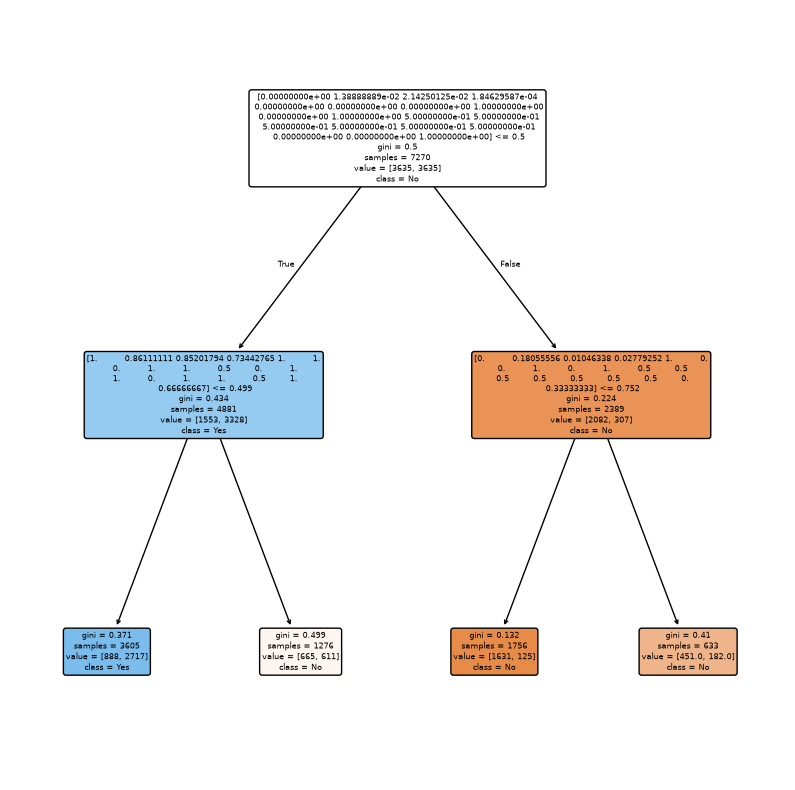

In [89]:
plt.figure(figsize=(10,10))

plot_tree(
    dc1,
    feature_names=X_train_resample,
    class_names=['No','Yes'],
    filled=True,
    rounded=True,
    fontsize=6
)

# RANDOM FOREST

In [90]:
from sklearn.ensemble import RandomForestClassifier

In [91]:
rf= RandomForestClassifier(n_estimators=100,random_state=42)

In [92]:
rf.fit(X_train_resample,y_train_resample)

y_pred_rf= rf.predict(X_test)

In [93]:
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           0       0.85      0.86      0.85      1539
           1       0.61      0.59      0.60       574

    accuracy                           0.78      2113
   macro avg       0.73      0.72      0.72      2113
weighted avg       0.78      0.78      0.78      2113



In [94]:
y_prob_rf= rf.predict_proba(X_test)[:,1]

In [95]:
roc_auc_score(y_test,y_prob_rf)

0.8347364572225504

In [96]:
# checking confusion matrix

In [97]:
confusion_matrix(y_test,y_pred_rf)

array([[1319,  220],
       [ 237,  337]])

# SUPPORT VECTOR MACHINE

In [98]:
from sklearn.svm import SVC

In [99]:
sv= SVC(kernel= 'rbf',probability=True,random_state=42)

In [100]:
sv.fit(X_train_resample,y_train_resample)

y_pred_sv = sv.predict(X_test)

c:\Users\shrey\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [101]:
print(classification_report(y_test,y_pred_sv))


              precision    recall  f1-score   support

           0       0.88      0.78      0.83      1539
           1       0.55      0.72      0.62       574

    accuracy                           0.76      2113
   macro avg       0.71      0.75      0.72      2113
weighted avg       0.79      0.76      0.77      2113



In [102]:
y_prob_sv= sv.predict_proba(X_test)[:,1]

# cross validation

In [103]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold,StratifiedKFold,cross_val_score 
from sklearn.model_selection import cross_validate

In [104]:
lg_pipeline = ImbPipeline([
    ('scaler',MinMaxScaler()),
    ('smote',SMOTE(random_state=42)),
    ('model',LogisticRegression(max_iter=1000))
])

In [105]:
cv= StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [106]:
# Evalute the score

In [107]:
score = cross_validate (
    lg_pipeline,
    X_train_resample,
    y_train_resample,
    cv = cv,
    scoring= ['accuracy','precision','recall','f1','roc_auc'],
    return_train_score=False
)


In [108]:
after_cv = pd.DataFrame({
    'Accuracy' :score['test_accuracy'],
    'Precison' : score['test_precision'],
    'Recall' : score['test_recall'],
    'F1': score['test_f1'],
    'Roc_auc': score['test_roc_auc']
})

In [109]:
after_cv.mean().round(4)

Accuracy    0.7671
Precison    0.7452
Recall      0.8121
F1          0.7771
Roc_auc     0.8468
dtype: float64

In [110]:
from imblearn.pipeline import Pipeline


#step -1  creating pipeline for random forest

rf_pipeline = Pipeline([
    ('scaler',MinMaxScaler()),
    ('smote',SMOTE(random_state=42)),
    ('model', RandomForestClassifier(random_state=42,n_jobs=1))
])

# step -2  defining paramtr grid

param_grid_rf ={
    'model__n_estimators':[100,200],
    'model__criterion':['gini','entropy'],
    'model__max_depth': [5,10,None],
    'model__min_samples_split':[2,5],
    'model__min_samples_leaf':[1,2]
    
}

# step- 3 cross validation

cv_rf= StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# importing tuning

from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
# step -4: hyperparamtr tuning 

grid_search_rf = GridSearchCV(
    estimator= rf_pipeline,
    param_grid= param_grid_rf,
    cv =cv_rf,
    scoring= 'f1',
    refit= True,
    n_jobs=-1
)

#  step-5 : training the model

grid_search_rf.fit(X_train,y_train)




,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__criterion': ['gini', 'entropy'], 'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... version

In [111]:
# step 6 : best parameter

grid_search_rf.best_params_

{'model__criterion': 'gini',
 'model__max_depth': 10,
 'model__min_samples_leaf': 2,
 'model__min_samples_split': 5,
 'model__n_estimators': 100}

In [112]:
grid_search_rf.best_score_

np.float64(0.6273723229428758)

In [113]:
best_estimator = grid_search_rf.best_estimator_

In [114]:
y_pred_rf_est = best_estimator.predict(X_test)

In [115]:
confusion_matrix(y_test,y_pred_rf_est)

array([[1233,  306],
       [ 150,  424]])

In [116]:
print(classification_report(y_test,y_pred_rf_est))

              precision    recall  f1-score   support

           0       0.89      0.80      0.84      1539
           1       0.58      0.74      0.65       574

    accuracy                           0.78      2113
   macro avg       0.74      0.77      0.75      2113
weighted avg       0.81      0.78      0.79      2113



# DECISION TREE HYPERPARAMTER

In [117]:
from imblearn.pipeline import Pipeline
# step 1: creating pipeline for decision tree
dt_pipeline = Pipeline([
    ('scaler',MinMaxScaler()),
    ('smote',SMOTE(random_state=42)),
    ('model', DecisionTreeClassifier(random_state=42))
])

# step -2  defining paramtr grid

param_grid_dt ={
    
    'model__criterion':['gini','entropy'],
    'model__max_depth': [5,10,None],
    'model__min_samples_split':[2,5],
    'model__min_samples_leaf':[1,2]
    
}

# step- 3 cross validation

cv_dt= StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# importing tuning

from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
# step -4: hyperparamtr tuning 

grid_search_dt = GridSearchCV(
    estimator= dt_pipeline,
    param_grid= param_grid_dt,
    cv =cv_dt,
    scoring= 'accuracy',
    verbose=1,
    n_jobs=-1
)

#  step-5 : training the model

grid_search_dt.fit(X_train,y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__criterion': ['gini', 'entropy'], 'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more abou

In [118]:
# step 6 : best parameter

grid_search_dt.best_params_

{'model__criterion': 'entropy',
 'model__max_depth': 10,
 'model__min_samples_leaf': 2,
 'model__min_samples_split': 2}

In [119]:
grid_search_dt.best_score_

np.float64(0.7620689655172413)

In [120]:
best_estimator_dt = grid_search_dt.best_estimator_

In [121]:
y_pred_dt_est = best_estimator_dt.predict(X_test)

In [122]:
confusion_matrix(y_test,y_pred_dt_est)

array([[1202,  337],
       [ 182,  392]])

In [123]:
print(classification_report(y_test,y_pred_dt_est))

              precision    recall  f1-score   support

           0       0.87      0.78      0.82      1539
           1       0.54      0.68      0.60       574

    accuracy                           0.75      2113
   macro avg       0.70      0.73      0.71      2113
weighted avg       0.78      0.75      0.76      2113



# SVM HYPERPARAMTER

In [124]:
from imblearn.pipeline import Pipeline
# step 1: creating pipeline for svm
svm_pipeline = Pipeline([
    ('scaler',MinMaxScaler()),
    ('smote',SMOTE(random_state=42)),
    ('model', DecisionTreeClassifier(random_state=42))
])

# step -2  defining paramtr grid

param_grid_svm ={
    
    'model__criterion':['gini','entropy'],
    'model__max_depth': [5,10,None],
    'model__min_samples_split':[2,5],
    'model__min_samples_leaf':[1,2]
    
}

# step- 3 cross validation

cv_svm= StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# importing tuning

from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
# step -4: hyperparamtr tuning 

grid_search_svm = GridSearchCV(
    estimator= svm_pipeline,
    param_grid= param_grid_svm,
    cv =cv_svm,
    scoring= 'accuracy',
    verbose=1,
    n_jobs=-1
)

#  step-5 : training the model

grid_search_svm.fit(X_train,y_train)

Fitting 5 folds for each of 24 candidates, totalling 120 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__criterion': ['gini', 'entropy'], 'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more abou

In [125]:
# step 6 : best parameter

grid_search_svm.best_params_

{'model__criterion': 'entropy',
 'model__max_depth': 10,
 'model__min_samples_leaf': 2,
 'model__min_samples_split': 2}

In [126]:
grid_search_svm.best_score_

np.float64(0.7620689655172413)

In [127]:
best_estimator_svm = grid_search_svm.best_estimator_

In [128]:
y_pred_svm_est = best_estimator_svm.predict(X_test)

In [129]:
confusion_matrix(y_test,y_pred_svm_est)

array([[1202,  337],
       [ 182,  392]])

In [130]:
print(classification_report(y_test,y_pred_svm_est))

              precision    recall  f1-score   support

           0       0.87      0.78      0.82      1539
           1       0.54      0.68      0.60       574

    accuracy                           0.75      2113
   macro avg       0.70      0.73      0.71      2113
weighted avg       0.78      0.75      0.76      2113



# Bagging technique on Random forest

In [131]:
from sklearn.ensemble import(
BaggingClassifier,
AdaBoostClassifier,
GradientBoostingClassifier
)

In [132]:
bagging_model= BaggingClassifier(
    estimator= RandomForestClassifier(),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# train

bagging_model.fit(X_train,y_train)

# predict

y_pred_bag = bagging_model.predict(X_test)
y_prob_bag = bagging_model.predict_proba(X_test)[:,-1]

# evalute
print('bagging accuracy',accuracy_score(y_test,y_pred_bag))
print(classification_report(y_test,y_pred_bag))
print('roc_auc',roc_auc_score(y_test,y_prob_bag))

bagging accuracy 0.8007572172266919
              precision    recall  f1-score   support

           0       0.83      0.92      0.87      1539
           1       0.69      0.49      0.57       574

    accuracy                           0.80      2113
   macro avg       0.76      0.70      0.72      2113
weighted avg       0.79      0.80      0.79      2113

roc_auc 0.8446737892608668


In [133]:
# apply boosting

In [134]:
ada_boost = AdaBoostClassifier(
    estimator=RandomForestClassifier(max_depth=5,min_samples_split=5,min_samples_leaf=2,n_jobs=1,),
    n_estimators=200,
    learning_rate=1.0,
    random_state=42
)

# training model

ada_boost.fit(X_train,y_train)

# prediction

y_pred_ada = ada_boost.predict(X_test)
y_prob_ada = ada_boost.predict_proba(X_test)[:,-1]

# 
print('bagging accuracy',accuracy_score(y_test,y_pred_ada))
print(classification_report(y_test,y_pred_ada))
print('roc_auc',roc_auc_score(y_test,y_prob_ada))


bagging accuracy 0.7657359204921912
              precision    recall  f1-score   support

           0       0.82      0.86      0.84      1539
           1       0.58      0.51      0.54       574

    accuracy                           0.77      2113
   macro avg       0.70      0.68      0.69      2113
weighted avg       0.76      0.77      0.76      2113

roc_auc 0.8056647943254704


In [135]:
# apply gradient boosting

In [136]:
gb_boost =GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)

# training

gb_boost.fit(X_train,y_train)

# prediction

y_pred_gb = gb_boost.predict(X_test)
y_prob_gb = gb_boost.predict_proba(X_test)[:,-1]

# evLAUTE

print('bagging accuracy',accuracy_score(y_test,y_pred_gb))
print(classification_report(y_test,y_pred_gb))
print('roc_auc',roc_auc_score(y_test,y_prob_gb))


bagging accuracy 0.7927117841930904
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1539
           1       0.65      0.52      0.58       574

    accuracy                           0.79      2113
   macro avg       0.74      0.71      0.72      2113
weighted avg       0.78      0.79      0.79      2113

roc_auc 0.8476577622919087


In [137]:
!pip install xgboost

In [138]:
from xgboost import XGBClassifier
xgb_boost = XGBClassifier(
     n_estimators=100,
     learning_rate=0.1,
    max_depth =5,
    eval_metric ='logloss',
    random_state=42,
    n_jobs=1
)

xgb_boost.fit(X_train,y_train)

y_pred_xgb = xgb_boost.predict(X_test)
y_prob_xgb = xgb_boost.predict_proba(X_test)[:,-1]

print('bagging accuracy',accuracy_score(y_test,y_pred_xgb))
print(classification_report(y_test,y_pred_xgb))
print('roc_auc',roc_auc_score(y_test,y_prob_xgb))


bagging accuracy 0.8021769995267393
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1539
           1       0.67      0.53      0.59       574

    accuracy                           0.80      2113
   macro avg       0.75      0.72      0.73      2113
weighted avg       0.79      0.80      0.79      2113

roc_auc 0.8545165986329872


In [139]:
grid_search_rf.best_params_

{'model__criterion': 'gini',
 'model__max_depth': 10,
 'model__min_samples_leaf': 2,
 'model__min_samples_split': 5,
 'model__n_estimators': 100}

In [140]:
import pickle

In [141]:
import joblib
joblib.dump(best_estimator,'churn_model.pkl')

['churn_model.pkl']

In [142]:
model = joblib.load('churn_model.pkl')

In [143]:
joblib.dump(mm,'scaler.pkl')

['scaler.pkl']

In [144]:
print(list(mm.feature_names_in_))

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
